评分
80    47
81    93
82    66
83    43
84    30
85    16
其他     5
Name: 评分, dtype: int64

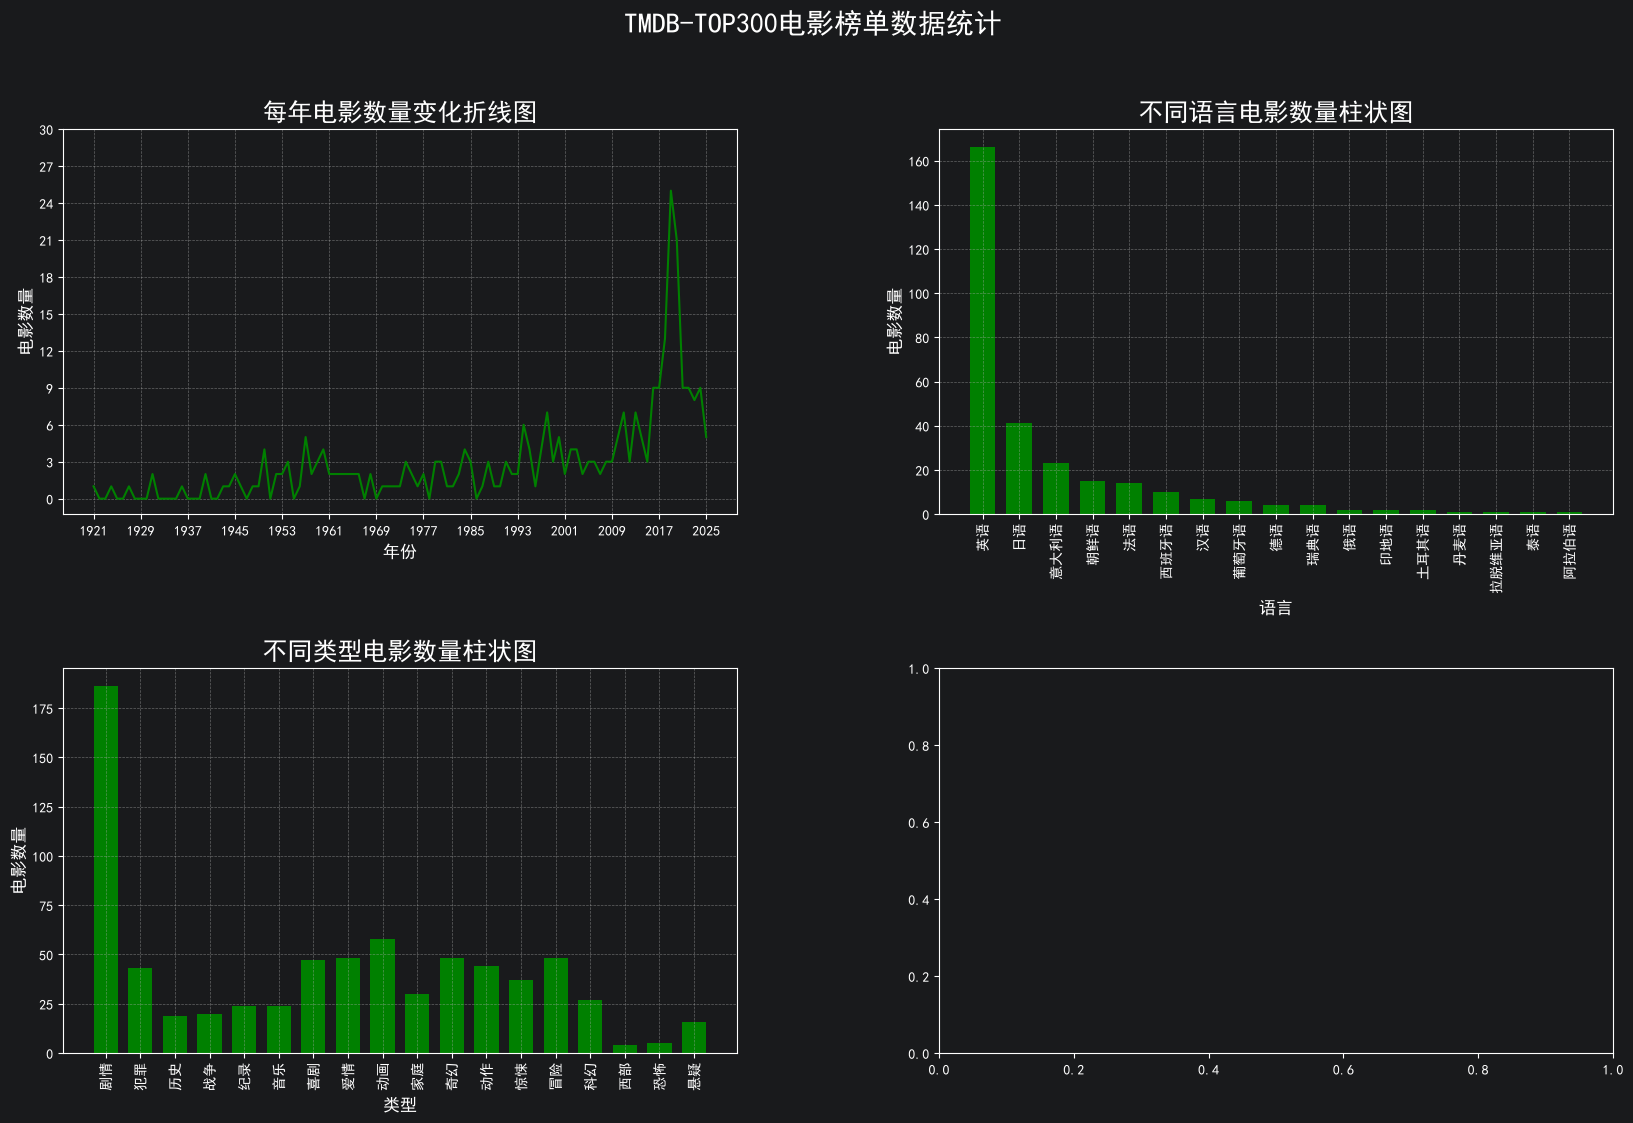

In [13]:
#-----------------------------------TMDB-TOP300电影榜单数据统计-----------------------------------
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes import Axes

# 展示中文
plt.rcParams['font.sans-serif'] = ['SimHei']

# 1. 准备工作：导入依赖库、配置运行时参数、创建子图完成基本布局、加载数据
# 创建子图
figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12), dpi=100)
figure.suptitle("TMDB-TOP300电影榜单数据统计", fontsize=20, x=0.5, y=0.98) # 设置主标题, x: 主标题水平位置, y: 主标题垂直位置
figure.subplots_adjust(wspace=0.3, hspace=0.4) # 调整子图之间的间距, wspace: 水平间距, hspace: 垂直间距
# 获取子图
axes1: Axes = axes[0][0]
axes2: Axes = axes[0][1]
axes3: Axes = axes[1][0]
axes4: Axes = axes[1][1]

# 加载数据
# int64: 整型数字(不支持空值)
# Int64: 整型数字(支持空值)
# float64: 浮点型数字(支持空值)
df = pd.read_csv("data/movies.csv",usecols=["电影名","年份","上映时间","类型","时长","评分","语言"], dtype={"年份": "Int64"})
# df.dtypes
df

# 2. 统计 TOP300 的电影中，每一年上映的电影数量的变化。（折线图）
# 2.1 缺失值/异常值的处理
# df.isnull().sum()
df["年份"] = df["年份"].fillna(df["上映时间"].str[0:4])

# 2.2 分组统计
year_count = df.groupby('年份')['年份'].count()

# 2.3 组装数据
# x 轴数据
# year_count`的索引只有有电影的年份，是断断续续的。
# 如果直接拿索引当 x，年份中间会跳过去，折线就不是连续时间线。
# 所以手动生成从最早到最晚的全部连续年份作为 x；找不到的年份用 .get填 0
# 所以不能用柱状图的方法,
min_year = year_count.index.min()
max_year = year_count.index.max()
x = [i for i in range(min_year, max_year+1)]

# y 轴数据
# 遍历所有连续年份，存在该年份就取电影数量，不存在则取 0，统一转为整数，生成 y 轴数据
y = [int(year_count.get(i, 0)) for i in x]

# 2.4 绘制折线图
axes1.plot(x, y, color='green')  # 折线图
axes1.set_title('每年电影数量变化折线图', fontsize=18)  # 添加子图标题
axes1.set_xlabel('年份', fontsize=12)  # 添加X轴标签
axes1.set_ylabel('电影数量', fontsize=12)  # 添加Y轴标签

axes1.set_xticks(x[::8])  # 设置X轴刻度间隔
y_ticks = [i for i in range(0, 31, 3)]
axes1.set_yticks(y_ticks)  # 设置Y轴刻度间隔
axes1.grid(linestyle='--', alpha=0.5)  # 添加网格线

# 3. 统计对比不同语言电影数量。（柱状图）
# 3.1 获取不同语言对应的电影数量
language_count = df.groupby('语言')['语言'].count().sort_values(ascending=False)

x_language = language_count.index.tolist()
y_language_count = language_count.values.tolist()

# 3.2 绘制柱状图
axes2.bar(x_language, y_language_count, color='green', width=0.7)  # 柱状图
axes2.set_title('不同语言电影数量柱状图', fontsize=18)  # 添加子图标题
axes2.set_xlabel('语言', fontsize=12)  # 添加X轴标签
axes2.set_ylabel('电影数量', fontsize=12)  # 添加Y轴标签
axes2.grid(linestyle='--', alpha=0.5)  # 添加网格线
axes2.tick_params(axis='x', rotation=90)  # 旋转X轴标签

# 4. 统计对比不同类型电影数量。（柱状图）
# 4.1 获取不同类型的电影数量 --> 用字典存储
type_count = {}  # {'剧情': 5, '犯罪': 3}

for types in df['类型'].str.split(','):  # ['剧情', '犯罪']
    for type in types:  # '剧情'
        if type in type_count: # 如果类型在字典中
            type_count[type] += 1 # 值加1
        else:
            type_count[type] = 1

# type_count.keys() --> type: <class 'dict_keys'>(视图对象, 跟着原字典实时变动) --> 不支持索引，需要转换为列表
# list() 用于转换为列表
x_types = list(type_count.keys())  # 类型列表
y_values = list(type_count.values())  # 数量列表

# 4.2 绘制柱状图
axes3.bar(x_types, y_values, color='green', width=0.7)  # 柱状图
axes3.set_title('不同类型电影数量柱状图', fontsize=18)  # 添加子图标题
axes3.set_xlabel('类型', fontsize=12)  # 添加X轴标签
axes3.set_ylabel('电影数量', fontsize=12)  # 添加Y轴标签
axes3.grid(linestyle='--', alpha=0.5)  # 添加网格线
axes3.tick_params(axis='x', rotation=90)  # 旋转X轴标签

# 5. 统计对比各部电影评分的比例。（饼状图）
# 5.1 获取各部电影评分的比例
score_count = df.groupby('评分')['评分'].count()


# 合并小数据(比例小于 2%) --> 其他
total = score_count.sum()
large_scores = score_count.loc[score_count >= total * 0.02] # 大数据, 比例 >= 2%
# large_score --> 不取 small_score 的部分
small_scores = score_count.loc[score_count < total * 0.02] # 小数据, 比例 < 2%
# small_score --> # 评分
#                   86     3
#                   87     2

# small_scores.shape 说明一共有多少行 --> 返回一个元组, (2,)
# small_scores.shape[0] --> shape[0]: 取这个元组里的第 1 个值, 也就是元素个数(行数 --> 2)
# if small_scores.shape[0] > 0 如果小数据行数大于 0, 就是有小数据
if small_scores.shape[0] > 0:
    # Series 本质就是: 索引(index)-> 值(values)的映射, 跟字典的[key -> value]结构是同一套思想
    # 没有的索引项, 可以直接新增
    large_scores['其他'] = small_scores.sum() # --> 把所有占比不足2%的分组数量求和, 新增其他索引项


scores = large_scores.index.tolist()  # 评分列表
scores_values = large_scores.values.tolist()  # 数量列表

# 5.2 绘制饼状图
axes4.pie(scores_values, labels=scores, autopct='%1.1f%%', startangle=0, radius=1.2)  # startangle 起始角度, radius=1.2 调整饼状图的半径
axes4.set_title('不同评分电影数量占比饼状图', fontsize=18)
axes4.legend(loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.2)) # bbox_to_anchor : 图例位置

# 5.3 保存图片
plt.savefig("data/TMDB_TOP300_movies_analysis.png")

plt.show() # 显示图表
